In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. analyze the data

In [2]:
df_c = pd.read_csv('customers.csv')
df_o = pd.read_csv('orders.csv')
df_p = pd.read_csv('products.csv')

In [3]:
df_c.head()

,customer_id,signup_date,city,channel
0,C0001,2025-05-17,Vienna,Organic
1,C0002,2023-07-26,Madrid,Referral
2,C0003,2025-09-25,Warsaw,Referral
3,C0004,2023-03-15,Madrid,Ads
4,C0005,2025-10-29,Warsaw,Organic


In [4]:
df_o.head()

,order_id,order_date,customer_id,product_id,quantity,discount_pct,status,payment_method
0,O3707,2025-06-29,C0155,P07,1,0%,Delivered,PayPal
1,O4308,2025-08-07,C0356,P07,1,0.0,Cancelled,Card
2,O4003,2025-07-17,C0002,P04,1,0.3,Delivered,Card
3,O2960,2025-05-08,C0244,P06,2,0.0,Delivered,Transfer
4,O2895,2025-05-04,C0168,P06,1,0.0,Delivered,PayPal


In [5]:
df_p.head(15)

,product_id,name,category,price,cost
0,P01,Headphones,Electronics,79.0,48.0
1,P02,Phone Case,Electronics,15.0,5.0
2,P03,Smart Speaker,Electronics,59.0,38.0
3,P04,Desk Lamp,Home,35.0,29.0
4,P05,Cookware Set,Home,"90,00",76.0
5,P06,Vacuum Bottle,Home,25.0,20.0
6,P07,T-Shirt,Clothing,20.0,7.0
7,P08,Jacket,Clothing,85.0,40.0
8,P09,Sneakers,Clothing,70.0,33.0
9,P10,Yoga Mat,Sports,30.0,12.0


In [6]:
print('Orders Missing Values') 
print(df_o.isna().sum())

print('Customers Missing Values') 
print(df_c.isna().sum())

print('Products Missing Values') 
print(df_p.isna().sum())


Orders Missing Values
order_id           0
order_date         0
customer_id       45
product_id         0
quantity           0
discount_pct       0
status             0
payment_method     0
dtype: int64
Customers Missing Values
customer_id    0
signup_date    0
city           0
channel        0
dtype: int64
Products Missing Values
product_id    0
name          0
category      0
price         0
cost          0
dtype: int64


In [7]:
print('Orders Duplicates') 
print(df_o.duplicated().sum())

print('Customers Duplicates') 
print(df_c.duplicated().sum())

print('Products Duplicates') 
print(df_p.duplicated().sum())

Orders Duplicates
25
Customers Duplicates
0
Products Duplicates
0


In [8]:
df_o.info()

<class 'pandas.DataFrame'>
RangeIndex: 6315 entries, 0 to 6314
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   order_id        6315 non-null   str  
 1   order_date      6315 non-null   str  
 2   customer_id     6270 non-null   str  
 3   product_id      6315 non-null   str  
 4   quantity        6315 non-null   int64
 5   discount_pct    6315 non-null   str  
 6   status          6315 non-null   str  
 7   payment_method  6315 non-null   str  
dtypes: int64(1), str(7)
memory usage: 645.9 KB


In [9]:
df_c.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   customer_id  400 non-null    str  
 1   signup_date  400 non-null    str  
 2   city         400 non-null    str  
 3   channel      400 non-null    str  
dtypes: str(4)
memory usage: 23.0 KB


In [10]:
df_p.info()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   product_id  12 non-null     str    
 1   name        12 non-null     str    
 2   category    12 non-null     str    
 3   price       12 non-null     str    
 4   cost        12 non-null     float64
dtypes: float64(1), str(4)
memory usage: 904.0 bytes


In [11]:
print(df_c['city'].value_counts())
print(df_c['channel'].value_counts())

city
Madrid     78
Rome       65
Paris      60
Vienna     57
Warsaw     54
Berlin     46
 warsaw     7
 berlin     5
 paris      5
MADRID      5
 vienna     4
 madrid     4
PARIS       3
ROME        2
 rome       2
VIENNA      2
WARSAW      1
Name: count, dtype: int64
channel
Organic     142
Ads         132
Referral    126
Name: count, dtype: int64


In [12]:
print(df_o['status'].value_counts())
print(df_o['payment_method'].value_counts())
print(df_o['discount_pct'].value_counts())

status
Delivered     5515
Returned       483
Cancelled      226
DELIVERED       29
delivered       25
 Delivered      24
returned         5
RETURNED         3
cancelled        2
CANCELLED        1
 Returned        1
 Cancelled       1
Name: count, dtype: int64
payment_method
Card        3124
PayPal      1636
Transfer    1555
Name: count, dtype: int64
discount_pct
0.0     3312
0.1     1099
0.05    1017
0.3      260
0.25     254
0.2      253
0%        57
5%        27
10%       16
25%       11
30%        9
Name: count, dtype: int64


In [13]:
df_o.describe()

,quantity
count,6315.000000
mean,1.619636
std,0.886170
min,-1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,4.000000


In [14]:
df_c.describe()

,customer_id,signup_date,city,channel
count,400,400,400,400
unique,400,338,17,3
top,C0001,2024-01-16,Madrid,Organic
freq,1,4,78,142


In [15]:
df_p.describe()

,cost
count,12.000000
mean,30.583333
std,19.653629
min,5.000000
25%,18.000000
50%,31.000000
75%,38.500000
max,76.000000


In [16]:
(df_o['quantity'] < 0).sum()

np.int64(12)

In [17]:
(df_o['discount_pct'].str.contains('%').sum())

np.int64(120)

In [18]:
df_p['price'].head(15)

0      79.0
1      15.0
2      59.0
3      35.0
4     90,00
5      25.0
6      20.0
7      85.0
8      70.0
9      30.0
10     60.0
11     45.0
Name: price, dtype: str

In [19]:
pd.to_datetime(df_o['order_date'], errors='coerce').isna().sum()

np.int64(70)

In [20]:
(~df_o['product_id'].isin(df_p['product_id'])).sum()

np.int64(15)

In [21]:
df_o['order_id'].duplicated().sum()

np.int64(25)

Problems found so far:

orders.csv
1. `customer_id` missing: 45 rows (`isna().sum()`)
2. `status` has 12 spellings instead of 3: 91 rows (`value_counts()`)
3. `discount_pct` mixed formats (`0.1` and `10%`): 120 rows (`.str.contains('%').sum()`)
4. `quantity` has negative values (-1): 12 rows (`(df_o['quantity'] < 0).sum()`)
5. `order_date` mixed formats: 70 rows become `NaT` (`to_datetime(errors='coerce')`)
6. `product_id` has unknown products (`P99`): 15 rows (`~isin()`)
7. `order_id` has duplicates: 25 rows (`duplicated().sum()`)

customers.csv
1. `city` has 17 spellings instead of 6 (case and spaces): 40 rows (`value_counts()`)

products.csv
1. `price` is `str` because one row uses a comma decimal (`90,00`): 1 row (printing the column)

# 2. Clean the data

In [22]:
def clean_customers(df_c):
    df_c = df_c.copy()
    df_c['city'] = df_c['city'].str.strip().str.title()
    df_c['signup_date'] = pd.to_datetime(df_c['signup_date'])

    return df_c
    

In [23]:
df_c_clean = clean_customers(df_c)

In [24]:
df_c_clean['city'].value_counts()

city
Madrid    87
Rome      69
Paris     68
Vienna    63
Warsaw    62
Berlin    51
Name: count, dtype: int64

In [25]:
df_c_clean['signup_date'].info()

<class 'pandas.Series'>
RangeIndex: 400 entries, 0 to 399
Series name: signup_date
Non-Null Count  Dtype         
--------------  -----         
400 non-null    datetime64[us]
dtypes: datetime64[us](1)
memory usage: 3.3 KB


In [26]:
def clean_products(df_p):
    df_p = df_p.copy()
    df_p['price'] = df_p['price'].str.replace(',', '.')
    df_p['price'] = df_p['price'].astype(float)

    return df_p

In [27]:
df_p_clean = clean_products(df_p)

In [28]:
df_p_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   product_id  12 non-null     str    
 1   name        12 non-null     str    
 2   category    12 non-null     str    
 3   price       12 non-null     float64
 4   cost        12 non-null     float64
dtypes: float64(2), str(3)
memory usage: 855.0 bytes


In [29]:
df_p_clean.head(15)

,product_id,name,category,price,cost
0,P01,Headphones,Electronics,79.0,48.0
1,P02,Phone Case,Electronics,15.0,5.0
2,P03,Smart Speaker,Electronics,59.0,38.0
3,P04,Desk Lamp,Home,35.0,29.0
4,P05,Cookware Set,Home,90.0,76.0
5,P06,Vacuum Bottle,Home,25.0,20.0
6,P07,T-Shirt,Clothing,20.0,7.0
7,P08,Jacket,Clothing,85.0,40.0
8,P09,Sneakers,Clothing,70.0,33.0
9,P10,Yoga Mat,Sports,30.0,12.0


In [30]:
def clean_orders(df_o, df_p):
    df_o = df_o.copy()
    
    df_o['status'] = df_o['status'].str.strip().str.title()

    has_pct = df_o['discount_pct'].str.contains('%')
    df_o['discount_pct'] = df_o['discount_pct'].str.replace('%', '').astype(float)
    df_o.loc[has_pct, 'discount_pct'] = df_o.loc[has_pct, 'discount_pct'] / 100

    df_o = df_o[df_o['quantity'] > 0]

    d1 = pd.to_datetime(df_o['order_date'], format='%Y-%m-%d', errors='coerce')
    d2 = pd.to_datetime(df_o['order_date'], format='%d.%m.%Y', errors='coerce')
    df_o['order_date'] = d1.fillna(d2)

    df_o = df_o[df_o['product_id'].isin(df_p['product_id'])]

    df_o = df_o.drop_duplicates(subset=['order_id'])

    return df_o

In [31]:
df_o_clean = clean_orders(df_o, df_p)

In [32]:
assert df_o_clean['quantity'].min() > 0
assert df_o_clean['order_date'].isna().sum() == 0
assert df_o_clean['discount_pct'].between(0,1).all()
assert df_o_clean['status'].nunique() == 3
assert df_o_clean['order_id'].duplicated().sum() == 0

# 3. Build one analysis table


In [33]:
df_op = pd.merge(df_o_clean, df_p_clean, on='product_id', how='left')

In [34]:
df_full = pd.merge(df_op, df_c_clean, on='customer_id', how='left')

In [35]:
df_full['revenue'] = df_full['price'] * df_full['quantity'] * (1 - df_full['discount_pct'])
df_full['cost_total'] = df_full['cost'] * df_full['quantity']
df_full['profit'] = df_full['revenue'] - df_full['cost_total']
df_full['margin'] = df_full['profit'] / df_full['revenue']

In [36]:
df_full[['revenue','cost_total','profit','margin']].describe()

,revenue,cost_total,profit,margin
count,6263.000000,6263.000000,6263.000000,6263.000000
mean,69.726122,42.007504,27.718617,0.407447
std,58.237249,38.149353,28.119137,0.241451
min,13.500000,5.000000,-52.000000,-0.206349
25%,28.000000,14.000000,10.000000,0.324895
50%,57.000000,33.000000,21.000000,0.466667
75%,84.500000,58.000000,37.000000,0.600000
max,360.000000,304.000000,180.000000,0.666667


In [37]:
df_sales = df_full[df_full['status'] == 'Delivered'].copy()

# 4. Revenue over time

In [38]:
df_sales.head()

,order_id,order_date,customer_id,product_id,quantity,discount_pct,status,payment_method,name,category,price,cost,signup_date,city,channel,revenue,cost_total,profit,margin
0,O3707,2025-06-29,C0155,P07,1,0.00,Delivered,PayPal,T-Shirt,Clothing,20.0,7.0,2023-06-04,Madrid,Organic,20.00,7.0,13.00,0.650000
2,O4003,2025-07-17,C0002,P04,1,0.30,Delivered,Card,Desk Lamp,Home,35.0,29.0,2023-07-26,Madrid,Referral,24.50,29.0,-4.50,-0.183673
3,O2960,2025-05-08,C0244,P06,2,0.00,Delivered,Transfer,Vacuum Bottle,Home,25.0,20.0,2023-09-26,Warsaw,Referral,50.00,40.0,10.00,0.200000
4,O2895,2025-05-04,C0168,P06,1,0.00,Delivered,PayPal,Vacuum Bottle,Home,25.0,20.0,2024-05-11,Warsaw,Referral,25.00,20.0,5.00,0.200000
5,O5819,2025-11-08,C0339,P08,1,0.05,Delivered,Card,Jacket,Clothing,85.0,40.0,2024-04-29,Madrid,Referral,80.75,40.0,40.75,0.504644


In [39]:
by_month = (df_sales[['revenue', 'profit']].groupby(df_sales['order_date'].dt.month)).sum()

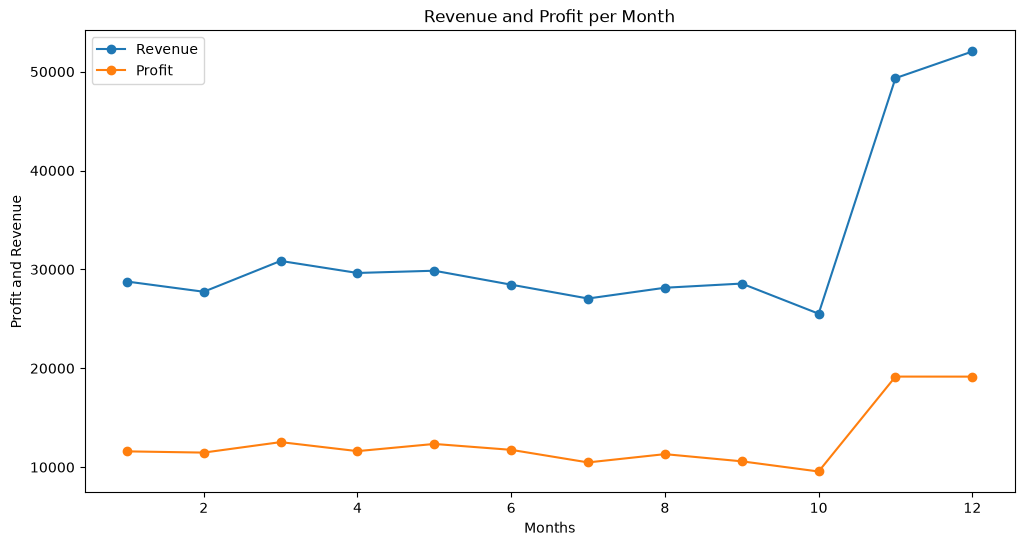

In [40]:
plt.figure(figsize=(12,6))
plt.plot(by_month.index, by_month.values, marker='o')
plt.title('Revenue and Profit per Month')
plt.xlabel('Months')
plt.ylabel('Profit and Revenue')
plt.legend(['Revenue', 'Profit'])
plt.show()

In [41]:
by_weeks = (df_sales[['revenue', 'profit']].groupby(df_sales['order_date'].dt.dayofweek)).sum()

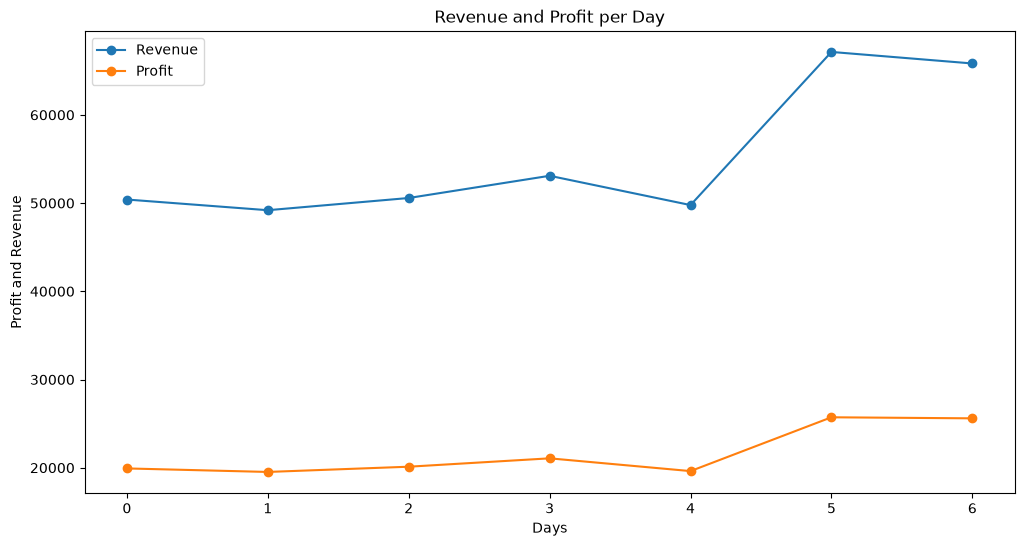

In [42]:
plt.figure(figsize=(12,6))
plt.plot(by_weeks.index, by_weeks.values, marker='o')
plt.title('Revenue and Profit per Day')
plt.xlabel('Days')
plt.ylabel('Profit and Revenue')
plt.legend(['Revenue', 'Profit'])
plt.show()

In [43]:
by_weekdays = by_weeks.loc[0:4, 'revenue'].mean()

In [44]:
by_weekends = by_weeks.loc[5:6, 'revenue'].mean()

In [45]:
weeks_pct = (by_weekends - by_weekdays) / by_weekdays * 100
print(weeks_pct)

31.360858704316318


An average weekend day brings about 31% more revenue than a weekday, so the difference is big enough to matter.

# 5. Where do we make and lose money?

In [46]:
df_rpm = df_sales[['revenue', 'profit']].groupby(df_sales['category']).sum()
df_rpm['margin'] = df_rpm['profit'] / df_rpm['revenue']

In [47]:
df_rpm.head()

,revenue,profit,margin
category,,,
Clothing,119924.00,64178.00,0.535156
Electronics,110698.05,44555.05,0.402492
Home,67946.75,1784.75,0.026267
Sports,87432.00,41053.00,0.469542


In [48]:
df_sales['half'] = np.where(df_sales['order_date'].dt.month.between(1,6), 'First Half', 'Second Half')

In [49]:
df_sales['half'].value_counts()

half
Second Half    3134
First Half     2411
Name: count, dtype: int64

In [50]:
df_cat_half = df_sales[['revenue', 'profit']].groupby([df_sales['category'], df_sales['half']]).sum()

In [51]:
df_cat_half['margin'] = df_cat_half['profit']  / df_cat_half['revenue']
df_cat_half.head(10)

revenue    profit    margin
category    half                                     
Clothing    First Half   54159.25  28844.25  0.532582
            Second Half  65764.75  35333.75  0.537275
Electronics First Half   48131.85  19499.85  0.405134
            Second Half  62566.20  25055.20  0.400459
Home        First Half   34763.00   5205.00  0.149728
            Second Half  33183.75  -3420.25 -0.103070
Sports      First Half   38277.00  17766.00  0.464143
            Second Half  49155.00  23287.00  0.473746

In [52]:
margin_by_half = df_cat_half['margin'].unstack()
margin_by_half.head()

half,First Half,Second Half
category,,
Clothing,0.532582,0.537275
Electronics,0.405134,0.400459
Home,0.149728,-0.103070
Sports,0.464143,0.473746


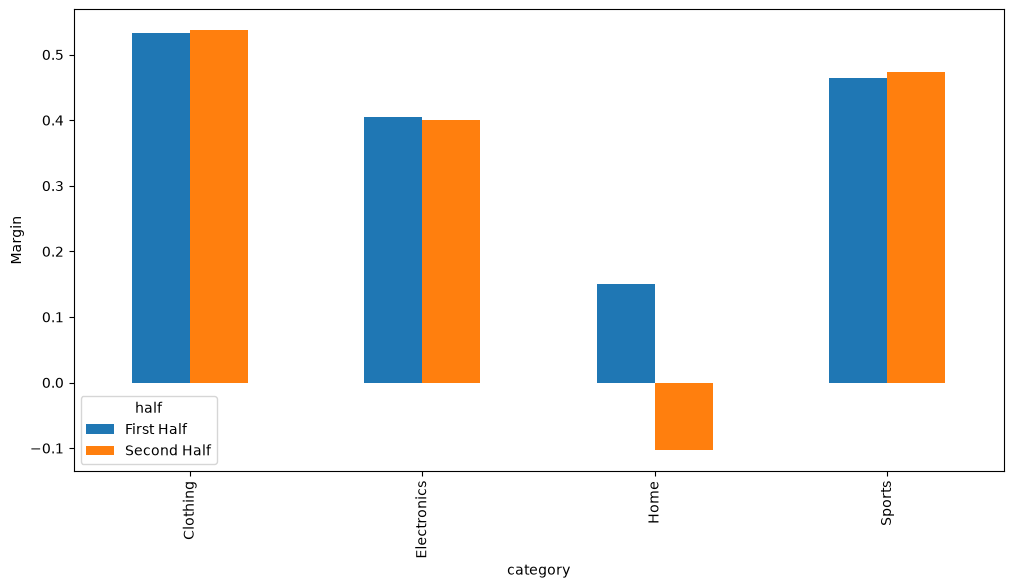

In [53]:
margin_by_half.plot(kind='bar', figsize=(12, 6))
plt.ylabel('Margin')
plt.show()

“Home’s margin falls from about +15% in the first half to about -10% in the second half, so it loses money, while Clothing, Electronics and Sports stay stable.

# 6. The discount question

In [54]:
avg_dsct = df_sales[['discount_pct']].groupby(df_sales['category']).mean()

In [55]:
avg_dsct.head()

,discount_pct
category,
Clothing,0.028859
Electronics,0.031173
Home,0.154794
Sports,0.028864


In [56]:
avg_dsct_half = df_sales[['discount_pct']].groupby([df_sales['category'], df_sales['half']]).mean()

In [57]:
avg_dsct_half.head(10)

discount_pct
category    half                     
Clothing    First Half       0.030294
            Second Half      0.027723
Electronics First Half       0.030700
            Second Half      0.031534
Home        First Half       0.029106
            Second Half      0.251261
Sports      First Half       0.030826
            Second Half      0.027386

In [58]:
df_home = df_sales[df_sales['category'] == 'Home' ].copy()
df_home['discount_pct'].value_counts()

discount_pct
0.00    338
0.30    245
0.25    242
0.20    227
0.10    109
0.05    101
Name: count, dtype: int64

In [59]:
df_home_margin = df_home[['revenue', 'profit']].groupby(df_home['discount_pct']).sum()
df_home_margin['margin'] = df_home_margin['profit'] / df_home_margin['revenue']

In [60]:
df_home_margin.head(6)

,revenue,profit,margin
discount_pct,,,
0.00,22580.00,3918.00,0.173516
0.05,6355.50,814.50,0.128157
0.10,5827.50,472.50,0.081081
0.20,10304.00,-313.00,-0.030377
0.25,12656.25,-1288.75,-0.101827
0.30,10223.50,-1818.50,-0.177875


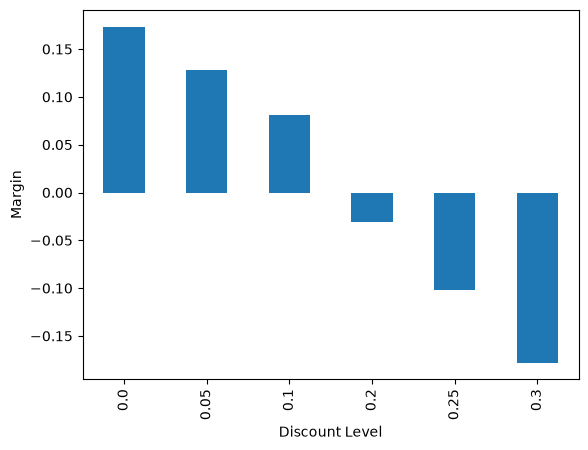

In [61]:
df_home_margin['margin'].plot(kind='bar')
plt.xlabel('Discount Level')
plt.ylabel('Margin')
plt.show()

Home’s margin falls as the discount rises, from +17% with no discount to -18% at a 30% discount, and it turns negative at a 20% discount.

In [62]:
df_home_20 = df_home[df_home['discount_pct'] >= 0.2].copy()

In [63]:
df_home_20['profit'].sum()

np.float64(-3420.25)

In [64]:
no_disc_profit = (df_home_20['price'] * df_home_20['quantity'] - df_home_20['cost_total']).sum()
actual_profit = df_home_20['profit'].sum()
lost_profit = no_disc_profit - actual_profit
print(lost_profit)

11176.25


The 714 Home orders with a discount of 20% or more lost about 11,200 in profit compared to selling at full price, assuming customers would have bought the same quantities without the discount.

# 7. Returns

In [65]:
df_full['is_returned'] = df_full['status'] == 'Returned'
df_full['is_returned'].value_counts()

is_returned
False    5773
True      490
Name: count, dtype: int64

In [66]:
return_rates = df_full['is_returned'].groupby(df_full['category']).mean()
return_rates.head(10)

category
Clothing       0.148770
Electronics    0.050000
Home           0.048375
Sports         0.051799
Name: is_returned, dtype: float64

In [67]:
return_rates_c = df_full['is_returned'].groupby(df_full['city']).mean()
return_rates_c.head(10)

city
Berlin    0.072829
Madrid    0.078871
Paris     0.069811
Rome      0.079545
Vienna    0.085657
Warsaw    0.083832
Name: is_returned, dtype: float64

In [68]:
df_full['city'].value_counts()

city
Madrid    1382
Paris     1060
Rome      1056
Vienna    1004
Warsaw    1002
Berlin     714
Name: count, dtype: int64

In [69]:
df_full['category'].value_counts()

category
Clothing       1788
Electronics    1700
Sports         1390
Home           1385
Name: count, dtype: int64

Clothing has a return rate of about 15% versus about 5% for the other categories, on 1,788 orders, so the difference is too large to be chance. City differences (7.0% to 8.6%) are small enough that they could be.

# 8. Best customers

In [70]:
top_customers = df_sales['profit'].groupby(df_sales['customer_id']).sum()
top_customers.nlargest(10)

customer_id
C0257    2591.20
C0354    2419.85
C0289    2373.10
C0007    2286.90
C0167    2271.45
C0053    2100.45
C0102    2035.45
C0306    1963.15
C0263    1951.50
C0178    1787.60
Name: profit, dtype: float64

In [71]:
top_customers_rev = df_sales['revenue'].groupby(df_sales['customer_id']).sum()
top_customers_rev.nlargest(10)

customer_id
C0257    6240.20
C0007    5850.90
C0289    5639.10
C0354    5581.85
C0167    5516.45
C0053    5115.45
C0102    5058.45
C0306    4967.15
C0165    4815.80
C0263    4544.50
Name: revenue, dtype: float64

In [72]:
n = int(len(top_customers) *0.1)
print(n)

38


In [73]:
top_customers.nlargest(n).sum() / top_customers.sum()

np.float64(0.37739700538323306)

The top 10% of customers generate about 38% of the profit, so the shop depends noticeably on a small group of customers.

In [74]:
customer_table = df_sales.groupby('customer_id').agg(
    total_profit = ('profit', 'sum'),
    n_orders = ('order_id', 'count'),
    channel = ('channel', 'first'),
    first_order=('order_date', 'min'),
    last_order=('order_date', 'max')
)
customer_table.head(17)

,total_profit,n_orders,channel,first_order,last_order
customer_id,,,,,
C0001,208.20,6,Organic,2025-03-11,2025-12-22
C0002,385.35,13,Referral,2025-03-08,2025-12-24
C0003,107.00,5,Referral,2025-05-31,2025-12-23
C0004,722.65,27,Ads,2025-01-13,2025-12-30
C0005,903.70,29,Organic,2025-01-24,2025-12-31
C0006,203.75,7,Ads,2025-02-10,2025-12-31
C0007,2286.90,83,Organic,2025-01-10,2025-12-27
C0008,469.30,7,Organic,2025-01-11,2025-12-17
C0009,50.00,2,Ads,2025-02-02,2025-11-25


In [75]:
per_customer = customer_table[['total_profit', 'n_orders']].groupby(customer_table['channel']).mean()
per_customer.head()

,total_profit,n_orders
channel,,
Ads,399.961240,14.046512
Organic,411.466423,15.197080
Referral,350.252479,13.314050


Organic customers are slightly the most profitable (about 411 vs 350 for Referral), but the differences between channels are small.

In [76]:
customers_more_than_one = (customer_table['n_orders'] > 1).mean() * 100
print(customers_more_than_one)

94.31524547803618


In [77]:
customer_table['is_repeat'] = customer_table['n_orders'] > 1
is_repeated_orders = customer_table['is_repeat'].groupby(customer_table['channel']).mean()
is_repeated_orders.head()

channel
Ads         0.937984
Organic     0.941606
Referral    0.950413
Name: is_repeat, dtype: float64

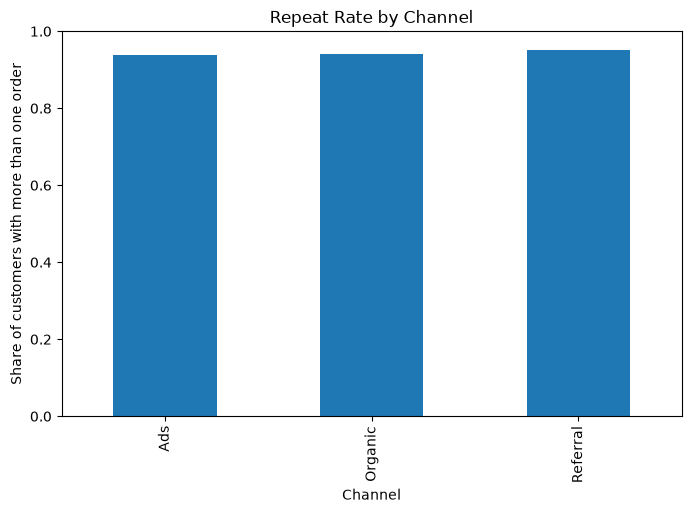

In [78]:
is_repeated_orders.plot(kind='bar', figsize=(8, 5))
plt.title('Repeat Rate by Channel')
plt.xlabel('Channel')
plt.ylabel('Share of customers with more than one order')
plt.ylim(0, 1)
plt.show()

About 94% to 95% of customers in every channel ordered more than once, so the channel makes no real difference to repeat buying.

# 10. Report function, dashboard and recommendation

In [79]:
sales_home = df_sales[df_sales['category'] == 'Home']
full_home = df_full[df_full['category'] == 'Home']

revenue = sales_home['revenue'].sum()
profit = sales_home['profit'].sum()
margin = profit / revenue
avg_discount = sales_home['discount_pct'].mean()
return_rate = full_home['is_returned'].mean()
n_orders = len(full_home)

In [80]:
print(revenue, profit, margin, avg_discount, return_rate, n_orders)

67946.75 1784.75 0.026266892824160094 0.15479397781299525 0.04837545126353791 1385


In [81]:
def category_report(df, category):
    df_cat = df[df['category'] == category]
    sales_cat = df_cat[df_cat['status'] == 'Delivered']

    revenue = sales_cat['revenue'].sum()
    profit = sales_cat['profit'].sum()

    monthly = sales_cat['profit'].groupby(sales_cat['order_date'].dt.month).sum()
    monthly.plot(kind='bar', figsize=(8, 5))
    plt.title(f'Monthly profit: {category}')
    plt.xlabel('Month')
    plt.ylabel('Profit')
    plt.savefig(f'report_{category}.png')
    plt.close()

    return {
        'revenue': revenue,
        'profit': profit,
        'margin': profit / revenue,
        'return_rate': df_cat['is_returned'].mean(),
        'avg_discount': sales_cat['discount_pct'].mean(),
        'n_orders': len(df_cat),
    }

In [82]:
category_report(df_full, 'Home')

{'revenue': np.float64(67946.75),
 'profit': np.float64(1784.75),
 'margin': np.float64(0.026266892824160094),
 'return_rate': np.float64(0.04837545126353791),
 'avg_discount': np.float64(0.15479397781299525),
 'n_orders': 1385}

In [83]:
results = {}
for cat in df_full['category'].unique():
    results[cat] = category_report(df_full, cat)

report_table = pd.DataFrame.from_dict(results, orient='index')
report_table

,revenue,profit,margin,return_rate,avg_discount,n_orders
Clothing,119924.00,64178.00,0.535156,0.148770,0.028859,1788
Home,67946.75,1784.75,0.026267,0.048375,0.154794,1385
Sports,87432.00,41053.00,0.469542,0.051799,0.028864,1390
Electronics,110698.05,44555.05,0.402492,0.050000,0.031173,1700


In [84]:
revenue_and_profit = df_sales[['revenue', 'profit']].groupby(df_sales['order_date'].dt.month).sum()

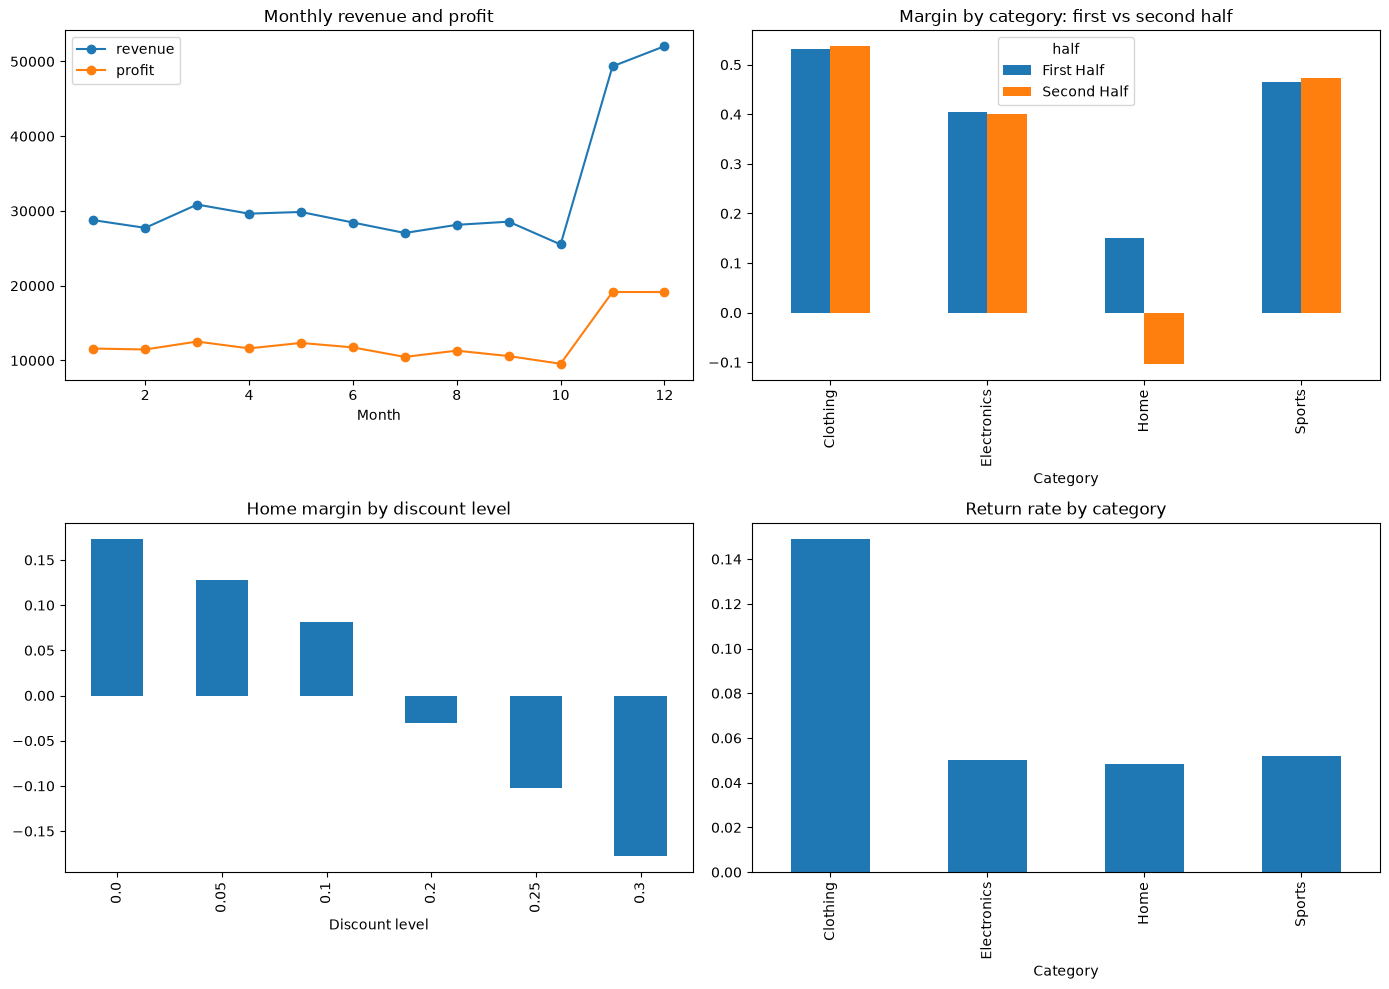

In [85]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

revenue_and_profit.plot(ax=axes[0, 0], marker='o')
axes[0, 0].set_title('Monthly revenue and profit')
axes[0, 0].set_xlabel('Month')

margin_by_half.plot(kind='bar', ax=axes[0, 1])
axes[0, 1].set_title('Margin by category: first vs second half')
axes[0, 1].set_xlabel('Category')

df_home_margin['margin'].plot(kind='bar', ax=axes[1, 0])
axes[1, 0].set_title('Home margin by discount level')
axes[1, 0].set_xlabel('Discount level')

return_rates.plot(kind='bar', ax=axes[1, 1])
axes[1, 1].set_title('Return rate by category')
axes[1, 1].set_xlabel('Category')

plt.tight_layout()
plt.savefig('dashboard.png')
plt.show()

## Report for the manager

Revenue is stable at about 28,000 per month from January to October and jumps to about 50,000 in November and December, but profit does not grow in the same way everywhere. Clothing (54%), Sports (47%) and Electronics (40%) earn healthy margins, while Home earns only 2.6% for the year. Home's margin is +15% in the first half and -10% in the second half, because its average discount rises from 3% to 25% after June, and every discount level of 20% or more loses money. Clothing has a high return rate (15% vs about 5% elsewhere), which is a smaller but real problem. Our best customers are very valuable: the top 10% of customers bring about 38% of total profit, and the top 10 by profit are almost the same as the top 10 by revenue. Organic customers are slightly the most profitable (about 411 per customer vs 350 for Referral), and about 94% of customers order more than once in every channel. **Recommendation:** before next year's sales season, cap Home discounts at 10%, because the 20% to 30% discounts cost about 11,200 in profit this year. This estimate assumes customers would have bought the same quantities at full price, so the real gain may be smaller.